# 中文版 Pipelined Neural Networks v7-2 — BERT 遞迴 Pipeline（修正版）
## v7-2 針對 v7 的四個改進
1. 修飾詞語境化：`BERT(modifier [SEP] target_text)`，不再只看孤立副詞。
2. 片語切割強化：由右向左找核心詞，並切出修飾詞鏈（modifier chain）。
3. `c_mod` 雙軸化：同時輸出 `Cmod-V` / `Cmod-A` 並視覺化分布。
4. V/A 互動建模：NNmod 加入 `[v, a, v*a, v-a]` 互動特徵。
## 架構設計（兩階段 Pipeline 保持不變）
```
Stage 1: BERT(word) -> NNword -> Int(w)
Stage 2: BERT(core) -> NNword(frozen) -> Int(w)
         BERT(modifier [SEP] core/phrase) -> NNmod -> Int(mod phrase)
```
多修飾詞時維持遞迴：由最靠近核心詞的修飾詞開始逐層往外套用。

## 0. 安裝套件

## 1. 設定執行環境與載入資料集

In [6]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from scipy.stats import kendalltau, spearmanr, pearsonr
from transformers import AutoTokenizer, AutoModel
from shared_setup import setup_runtime
CHINESE_FONT, device = setup_runtime()
# ---- 資料集路徑設定 ----
DATASETS = {
    'word': ('ChineseEmoBank/CVAW_SD/CVAW_all_SD.csv', 'Word', '詞彙'),
    'phrase': ('ChineseEmoBank/CVAP_SD/CVAP_all_SD.csv', 'Phrase', '片語'),
    'text': ('ChineseEmoBank/CVAS_SD/CVAS_all.csv', 'Text', '文本／句子'),
}
def read_csv_robust(path, sep='\t'):
    for enc in ['utf-8', 'utf-8-sig', 'big5', 'gb18030', 'cp950']:
        try:
            df = pd.read_csv(path, sep=sep, encoding=enc)
            print(f'  -> {path.split("/")[-1]} 使用編碼: {enc}')
            return df
        except (UnicodeDecodeError, UnicodeError):
            continue
    return pd.read_csv(path, sep=sep, encoding='utf-8', encoding_errors='replace')
cvaw = read_csv_robust(DATASETS['word'][0])
cvap = read_csv_robust(DATASETS['phrase'][0])
cvas = read_csv_robust(DATASETS['text'][0])
print(f'CVAW: {len(cvaw)}  CVAP: {len(cvap)}  CVAS: {len(cvas)}')

圖表字型：Noto Sans CJK TC
使用裝置：mps
  -> CVAW_all_SD.csv 使用編碼: utf-8
  -> CVAP_all_SD.csv 使用編碼: utf-8
  -> CVAS_all.csv 使用編碼: utf-8
CVAW: 5512  CVAP: 2250  CVAS: 2583


## 2. 資料前處理
v7-2 進一步加入否定詞範圍規則（例如「不是很」「並不太」），
提升複合修飾詞切割的穩定性，減少誤切。

In [7]:
def normalize_va(df, val_col='Valence_Mean', aro_col='Arousal_Mean'):
    df = df.copy()
    df[val_col] = pd.to_numeric(df[val_col], errors='coerce')
    df[aro_col] = pd.to_numeric(df[aro_col], errors='coerce')
    before = len(df)
    df = df.dropna(subset=[val_col, aro_col]).reset_index(drop=True)
    if before - len(df) > 0:
        print(f'  ⚠ 清除 {before-len(df)} 筆髒資料')
    df['valence'] = (df[val_col] - 1) / 8.0
    df['arousal'] = (df[aro_col] - 1) / 8.0
    return df
cvaw = normalize_va(cvaw)
cvap = normalize_va(cvap)
cvas = normalize_va(cvas)
# CVAP 短語切割：由右向左找核心詞 + 否定詞範圍規則
cvaw_word_set = set(cvaw['Word'].astype(str).tolist())
max_core_len = max(len(w) for w in cvaw_word_set)
# 否定詞與程度詞（長詞優先匹配）
NEGATION_CUES = {
    '不是很', '並不太', '並不是', '不怎麼', '不太', '不是', '並不', '沒有', '沒', '不', '無', '未', '別', '勿'
}
DEGREE_CUES = {
    '超級', '極為', '非常', '相當', '十分', '更加', '格外', '特別', '有點', '稍微', '很', '太', '更', '極', '超'
}
# 常見多詞修飾鏈，優先整體匹配
COMPOSITE_MODIFIERS = {
    '不是很', '並不太', '並不是很', '沒有很', '不怎麼', '不太'
}
MODIFIER_LEXICON = sorted(
    COMPOSITE_MODIFIERS | NEGATION_CUES | DEGREE_CUES,
    key=len,
    reverse=True
)
def normalize_text(s):
    s = str(s).strip()
    for ch in '，。！？、,.!?;；：「」『』（）() ':
        s = s.replace(ch, '')
    return s
def split_modifier_chain(modifier_text):
    """
    規則切分：
    1) 優先匹配複合否定程度詞（如 不是很/並不太）
    2) 次優先匹配一般否定或程度詞
    3) 未知片段退回單字，避免直接丟失資訊
    """
    txt = normalize_text(modifier_text)
    if not txt:
        return []
    mods = []
    i = 0
    while i < len(txt):
        matched = None
        for tok in MODIFIER_LEXICON:
            if txt.startswith(tok, i):
                matched = tok
                break
        if matched is None:
            matched = txt[i:i+1]
        mods.append(matched)
        i += len(matched)
    # 後處理：若出現「不是 + 很」「並不 + 太」再合併回範圍詞
    merged = []
    j = 0
    while j < len(mods):
        if j + 1 < len(mods):
            pair = mods[j] + mods[j + 1]
            if pair in COMPOSITE_MODIFIERS:
                merged.append(pair)
                j += 2
                continue
        merged.append(mods[j])
        j += 1
    return merged
def split_phrase(phrase, cvaw_words):
    phrase = normalize_text(phrase)
    candidates = []
    upper = min(max_core_len, len(phrase) - 1)
    for core_len in range(upper, 0, -1):
        core = phrase[-core_len:]
        modifier = phrase[:-core_len]
        if core in cvaw_words and len(modifier) > 0:
            mod_tokens = split_modifier_chain(modifier)
            neg_hits = sum(t in NEGATION_CUES for t in mod_tokens)
            deg_hits = sum(t in DEGREE_CUES for t in mod_tokens)
            # 先偏好含關鍵修飾詞，再偏好較長核心詞
            score = (neg_hits + deg_hits, neg_hits, core_len)
            candidates.append((score, modifier, core, mod_tokens))
    if candidates:
        _, modifier, core, mod_tokens = max(candidates, key=lambda x: x[0])
        return modifier, core, mod_tokens
    return None, None, []
mods, cores, mod_chains = [], [], []
for phrase in cvap['Phrase']:
    m, c, chain = split_phrase(phrase, cvaw_word_set)
    mods.append(m)
    cores.append(c)
    mod_chains.append(chain)
cvap['modifier'] = mods
cvap['core_word'] = cores
cvap['modifier_chain'] = mod_chains
cvap_aligned = cvap.dropna(subset=['modifier', 'core_word']).copy()
print(f'CVAP 對齊: {len(cvap_aligned)} / {len(cvap)} 筆')
print('切割示例（前 5 筆）:')
print(cvap_aligned[['Phrase', 'modifier', 'core_word', 'modifier_chain']].head().to_string(index=False))
# 8:2 切分
cvaw_train, cvaw_test = train_test_split(cvaw,         test_size=0.2, random_state=42)
cvap_train, cvap_test = train_test_split(cvap_aligned, test_size=0.2, random_state=42)
print(f'CVAW 訓練:{len(cvaw_train)}  測試:{len(cvaw_test)}')
print(f'CVAP 訓練:{len(cvap_train)}  測試:{len(cvap_test)}')

CVAP 對齊: 2249 / 2250 筆
切割示例（前 5 筆）:
Phrase modifier core_word modifier_chain
   怪八卦        怪        八卦            [怪]
  更加小心       更加        小心           [更加]
  格外小心       格外        小心           [格外]
  特別小心       特別        小心           [特別]
  極為小心       極為        小心           [極為]
CVAW 訓練:4409  測試:1103
CVAP 訓練:1799  測試:450


In [8]:
# 規則切割 sanity check（否定詞範圍）
probe_phrases = [
    '不是很開心',
    '並不太滿意',
    '不怎麼快樂',
    '沒有很失望',
    '非常開心',
]
print('=== Modifier Scope Sanity Check ===')
for p in probe_phrases:
    m, c, chain = split_phrase(p, cvaw_word_set)
    print(f'{p:8s} -> modifier={m}, core={c}, chain={chain}')

=== Modifier Scope Sanity Check ===
不是很開心    -> modifier=不是很, core=開心, chain=['不是很']
並不太滿意    -> modifier=並不太, core=滿意, chain=['並不太']
不怎麼快樂    -> modifier=不怎麼, core=快樂, chain=['不怎麼']
沒有很失望    -> modifier=沒有很, core=失望, chain=['沒有很']
非常開心     -> modifier=非常, core=開心, chain=['非常']


## 3. 載入中文 BERT
v7-2 除了單詞向量，也新增「修飾詞 + 被修飾詞」的 pair 向量：  
`BERT(modifier [SEP] target_text)`，讓 NNmod 具備語境感知能力。

In [9]:
BERT_NAME = 'hfl/chinese-bert-wwm-ext'
print(f'載入 {BERT_NAME}（約需 1~2 分鐘）...')
tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
bert_model = AutoModel.from_pretrained(BERT_NAME).to(device)
BERT_DIM = bert_model.config.hidden_size
print(f'✅ 載入完成 | hidden size: {BERT_DIM}')
@torch.no_grad()
def get_bert_vec(text):
    """
    單輸入 BERT [CLS]。
    用於核心詞的 base 情緒表示。
    """
    bert_model.eval()
    enc = tokenizer(
        text, return_tensors='pt',
        padding=True, truncation=True, max_length=16
    ).to(device)
    out = bert_model(**enc)
    cls_vec = out.last_hidden_state[:, 0, :].squeeze(0)
    return cls_vec.cpu().numpy().astype(np.float32)
@torch.no_grad()
def get_bert_pair_vec(modifier, target_text):
    """
    語境化修飾詞向量：BERT(modifier [SEP] target_text)
    讓 NNmod 感知修飾詞正在修飾哪個詞/片語。
    """
    bert_model.eval()
    enc = tokenizer(
        modifier,
        target_text,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=24
    ).to(device)
    out = bert_model(**enc)
    cls_vec = out.last_hidden_state[:, 0, :].squeeze(0)
    return cls_vec.cpu().numpy().astype(np.float32)
# 批次版本（訓練時效率更高）
@torch.no_grad()
def get_bert_vecs_batch(texts, batch_size=64):
    bert_model.eval()
    all_vecs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        enc = tokenizer(
            batch, return_tensors='pt',
            padding=True, truncation=True, max_length=16
        ).to(device)
        out = bert_model(**enc)
        cls = out.last_hidden_state[:, 0, :]
        all_vecs.append(cls.cpu().numpy())
    return np.concatenate(all_vecs, axis=0).astype(np.float32)
@torch.no_grad()
def get_bert_pair_vecs_batch(modifiers, targets, batch_size=64):
    bert_model.eval()
    all_vecs = []
    n = len(modifiers)
    for i in range(0, n, batch_size):
        b_mod = modifiers[i:i+batch_size]
        b_tgt = targets[i:i+batch_size]
        enc = tokenizer(
            b_mod,
            b_tgt,
            return_tensors='pt',
            padding=True,
            truncation=True,
            max_length=24
        ).to(device)
        out = bert_model(**enc)
        cls = out.last_hidden_state[:, 0, :]
        all_vecs.append(cls.cpu().numpy())
    return np.concatenate(all_vecs, axis=0).astype(np.float32)
# 測試
v1 = get_bert_vec('開心')
v2 = get_bert_vec('難過')
pair_v = get_bert_pair_vec('非常', '開心')
sim_happy_sad = float(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)))
print(f'開心 vs 難過 cosine: {sim_happy_sad:.4f}')
print(f'BERT 向量維度: {v1.shape} | pair 向量維度: {pair_v.shape}')

載入 hfl/chinese-bert-wwm-ext（約需 1~2 分鐘）...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: hfl/chinese-bert-wwm-ext
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ 載入完成 | hidden size: 768
開心 vs 難過 cosine: 0.8179
BERT 向量維度: (768,) | pair 向量維度: (768,)


## 4. 模型定義
### NNword head：BERT 向量 → VA 值
維持單詞基準情緒估計。
### NNmod：語境化修飾 + V/A 互動
輸入改為 `BERT(modifier [SEP] target_text)`，並加入 `v, a, v*a, v-a` 互動特徵，
讓 Valence/Arousal 的偏移可共享語意表示、降低獨立建模限制。

In [14]:
class NNword(nn.Module):
    """
    v7-2 版 NNword：BERT [CLS] → Valence / Arousal
    輸入：BERT 768 維向量（單詞）
    輸出：val, aro ∈ [0,1]
    """
    def __init__(self, bert_dim=768):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(bert_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )
    def forward(self, bert_vec):
        out = torch.sigmoid(self.net(bert_vec))
        return out[:, 0:1], out[:, 1:2]
class NNmod(nn.Module):
    """
    v7-2 版 NNmod：語境化修飾 + V/A 互動建模
    輸入：
      1) Int_val(w), Int_aro(w)
      2) BERT(modifier [SEP] target_text) 的語境向量
    設計重點：
      - delta 由 shared hidden 同時決定 val/aro（共享表示，允許耦合）
      - 加入 [v, a, v*a, v-a] 互動特徵
      - 回傳 c_mod_v / c_mod_a，便於雙維度分析
      - 使用 LayerNorm 以支援遞迴鏈訓練時的 batch size=1
    """
    def __init__(self, bert_dim=768):
        super().__init__()
        feat_dim = bert_dim + 4
        self.fc1 = nn.Linear(feat_dim, 192)
        self.fc2 = nn.Linear(192, 64)
        self.fc3 = nn.Linear(64, 2)
        self.ln1 = nn.LayerNorm(192)
        self.ln2 = nn.LayerNorm(64)
        self.drop = nn.Dropout(0.1)
        for layer in [self.fc1, self.fc2, self.fc3]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    def forward(self, int_val, int_aro, bert_mod_ctx):
        va_feat = torch.cat([
            int_val,
            int_aro,
            int_val * int_aro,
            int_val - int_aro
        ], dim=1)
        x = torch.cat([bert_mod_ctx, va_feat], dim=1)
        h = torch.relu(self.ln1(self.fc1(x)))
        h = self.drop(h)
        h = torch.relu(self.ln2(self.fc2(h)))
        delta = torch.tanh(self.fc3(h)) * 0.5
        delta_v = delta[:, 0:1]
        delta_a = delta[:, 1:2]
        out_v = torch.sigmoid(torch.logit(int_val.clamp(0.01, 0.99)) + delta_v * 3)
        out_a = torch.sigmoid(torch.logit(int_aro.clamp(0.01, 0.99)) + delta_a * 3)
        c_mod_v = delta_v + 0.5
        c_mod_a = delta_a + 0.5
        return out_v, out_a, c_mod_v, c_mod_a
print('NNword / NNmod（v7-2）定義完成')

NNword / NNmod（v7-2）定義完成


## 5. 預先計算所有 BERT 向量（含遞迴鏈）
除了 core word 向量，也快取遞迴鏈每一步需要的 pair context 向量：  
`modifier [SEP] current_phrase`，供 Stage 2 直接訓練多層遞迴鏈。

In [11]:
print('預先計算 CVAW 訓練集詞向量...')
word_train_vecs = get_bert_vecs_batch(cvaw_train['Word'].tolist())
word_train_val  = cvaw_train['valence'].values.astype(np.float32)
word_train_aro  = cvaw_train['arousal'].values.astype(np.float32)
print('預先計算 CVAW 測試集詞向量...')
word_test_vecs  = get_bert_vecs_batch(cvaw_test['Word'].tolist())
word_test_val   = cvaw_test['valence'].values.astype(np.float32)
word_test_aro   = cvaw_test['arousal'].values.astype(np.float32)
print('建立遞迴鏈訓練樣本（含 context cache）...')
core_cache = {}
pair_cache = {}
def get_core_vec_cached(word):
    if word not in core_cache:
        core_cache[word] = get_bert_vec(word)
    return core_cache[word]
def get_pair_vec_cached(modifier, target):
    key = (modifier, target)
    if key not in pair_cache:
        pair_cache[key] = get_bert_pair_vec(modifier, target)
    return pair_cache[key]
def build_recursive_chain_samples(df):
    samples = []
    for _, row in df.iterrows():
        core = str(row['core_word'])
        chain = row['modifier_chain'] if isinstance(row['modifier_chain'], list) else []
        if len(chain) == 0:
            chain = [str(row['modifier'])]
        cur_phrase = core
        ctx_chain = []
        # 由最靠近核心詞者先作用，因此反向展開
        for mod in reversed(chain):
            mod = str(mod)
            ctx_chain.append(get_pair_vec_cached(mod, cur_phrase))
            cur_phrase = mod + cur_phrase
        samples.append({
            'core_word': core,
            'full_phrase': str(row['Phrase']),
            'mods_outer_to_inner': chain,
            'ctx_chain': ctx_chain,
            'core_vec': get_core_vec_cached(core),
            'valence': float(row['valence']),
            'arousal': float(row['arousal']),
        })
    return samples
train_chain_samples = build_recursive_chain_samples(cvap_train)
test_chain_samples  = build_recursive_chain_samples(cvap_test)
# 保留舊變數名稱方便後續 cell 相容
core_train_vecs = np.stack([s['core_vec'] for s in train_chain_samples]).astype(np.float32)
core_test_vecs  = np.stack([s['core_vec'] for s in test_chain_samples]).astype(np.float32)
phrase_train_val = np.array([s['valence'] for s in train_chain_samples], dtype=np.float32)
phrase_train_aro = np.array([s['arousal'] for s in train_chain_samples], dtype=np.float32)
phrase_test_val  = np.array([s['valence'] for s in test_chain_samples], dtype=np.float32)
phrase_test_aro  = np.array([s['arousal'] for s in test_chain_samples], dtype=np.float32)
# Stage 1 張量（維持不變）
wt_v = torch.tensor(word_train_vecs).to(device)
wt_y_v = torch.tensor(word_train_val).unsqueeze(1).to(device)
wt_y_a = torch.tensor(word_train_aro).unsqueeze(1).to(device)
chain_lens = np.array([len(s['ctx_chain']) for s in train_chain_samples])
print(f'詞訓練: {wt_v.shape}')
print(f'遞迴鏈訓練樣本: {len(train_chain_samples)}  測試樣本: {len(test_chain_samples)}')
print(f'訓練鏈長度: mean={chain_lens.mean():.2f}, max={chain_lens.max()}, min={chain_lens.min()}')
print(f'cache | core: {len(core_cache)}  pair: {len(pair_cache)}')

預先計算 CVAW 訓練集詞向量...
預先計算 CVAW 測試集詞向量...
建立遞迴鏈訓練樣本（含 context cache）...
詞訓練: torch.Size([4409, 768])
遞迴鏈訓練樣本: 1799  測試樣本: 450
訓練鏈長度: mean=1.97, max=4, min=1
cache | core: 335  pair: 3387


## 6. Stage 1：訓練 NNword（BERT 向量 → VA）

=== Stage 1：訓練 NNword ===
Epoch  10/50 | Loss: 0.005556
Epoch  20/50 | Loss: 0.002790
Epoch  30/50 | Loss: 0.002083
Epoch  40/50 | Loss: 0.001283
Epoch  50/50 | Loss: 0.001115


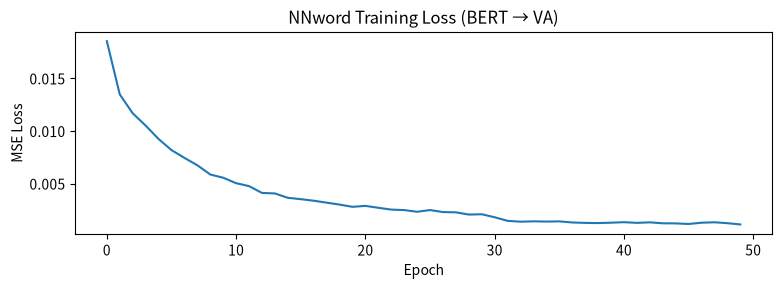

Stage 1 完成


In [15]:
from torch.utils.data import TensorDataset, DataLoader
model_word = NNword(BERT_DIM).to(device)
opt_word   = optim.AdamW(model_word.parameters(), lr=1e-3, weight_decay=0.01)
sch_word   = optim.lr_scheduler.StepLR(opt_word, step_size=30, gamma=0.5)
# DataLoader（batch training 讓 BatchNorm 正常運作）
word_ds = TensorDataset(wt_v, wt_y_v, wt_y_a)
word_dl = DataLoader(word_ds, batch_size=64, shuffle=True)
print('=== Stage 1：訓練 NNword ===')
N_EPOCHS_WORD = 50
losses_w = []
for epoch in range(N_EPOCHS_WORD):
    model_word.train()
    epoch_loss = 0.0
    for bvec, by_v, by_a in word_dl:
        pred_v, pred_a = model_word(bvec)
        loss = 0.5 * ((pred_v - by_v)**2 + (pred_a - by_a)**2).mean()
        opt_word.zero_grad()
        loss.backward()
        opt_word.step()
        epoch_loss += loss.item()
    sch_word.step()
    avg = epoch_loss / len(word_dl)
    losses_w.append(avg)
    if (epoch+1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_WORD} | Loss: {avg:.6f}')
plt.figure(figsize=(8,3))
plt.plot(losses_w)
plt.title('NNword Training Loss (BERT → VA)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.tight_layout(); plt.show()
print('Stage 1 完成')

## 7. Stage 2：訓練 NNmod（NNword 凍結，直接訓練遞迴鏈）
**v7-2 遞迴鏈訓練流程：**
1. NNword(BERT(core_word)) → Int(w)
2. 由最靠近核心詞的修飾詞開始，逐層遞迴：
   NNmod(Int(current), BERT(modifier [SEP] current_phrase))
3. 以最終 Int(full_phrase) 對齊片語標註 VA
NNword 仍凍結，只訓練 NNmod；但現在訓練時就會展開多層鏈。

=== Stage 2：訓練 NNmod（NNword 凍結，直接遞迴鏈訓練）===
流程：BERT(core) → NNword → Int(w) → NNmod(遞迴多步) → Int(full phrase)
Epoch  20/100 | Loss: 0.003664
Epoch  40/100 | Loss: 0.002465
Epoch  60/100 | Loss: 0.001905
Epoch  80/100 | Loss: 0.001642
Epoch 100/100 | Loss: 0.001363


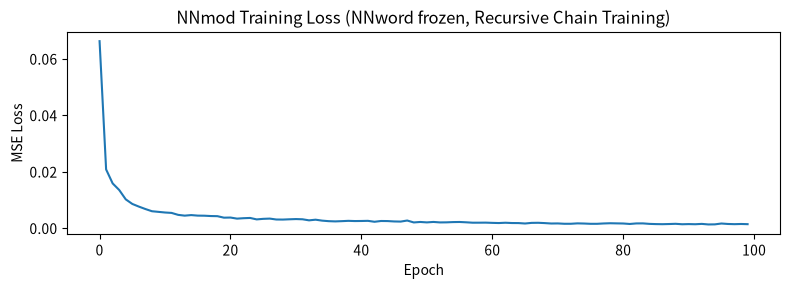

Stage 2 完成


In [16]:
model_mod = NNmod(BERT_DIM).to(device)
# 凍結 NNword
for param in model_word.parameters():
    param.requires_grad = False
opt_mod = optim.AdamW(model_mod.parameters(), lr=3e-3, weight_decay=1e-4)
print('=== Stage 2：訓練 NNmod（NNword 凍結，直接遞迴鏈訓練）===')
print('流程：BERT(core) → NNword → Int(w) → NNmod(遞迴多步) → Int(full phrase)')
N_EPOCHS_MOD = 100
losses_m = []
grad_accum_steps = 16
for epoch in range(N_EPOCHS_MOD):
    model_mod.train()
    model_word.eval()
    epoch_loss = 0.0
    idxs = np.random.permutation(len(train_chain_samples))
    opt_mod.zero_grad()
    for step_i, si in enumerate(idxs, start=1):
        s = train_chain_samples[si]
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        y_v = torch.tensor([[s['valence']]], dtype=torch.float32, device=device)
        y_a = torch.tensor([[s['arousal']]], dtype=torch.float32, device=device)
        # Step 1：核心詞先經 NNword（固定）
        with torch.no_grad():
            cur_v, cur_a = model_word(core_t)
        # Step 2：沿遞迴鏈逐步套用 NNmod（每步語境都不同）
        for ctx_np in s['ctx_chain']:
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, _, _ = model_mod(cur_v, cur_a, ctx_t)
        # 只用最終 full phrase 監督
        loss = 0.5 * ((cur_v - y_v)**2 + (cur_a - y_a)**2).mean()
        (loss / grad_accum_steps).backward()
        epoch_loss += loss.item()
        if (step_i % grad_accum_steps == 0) or (step_i == len(idxs)):
            torch.nn.utils.clip_grad_norm_(model_mod.parameters(), max_norm=1.0)
            opt_mod.step()
            opt_mod.zero_grad()
    avg = epoch_loss / len(train_chain_samples)
    losses_m.append(avg)
    if (epoch + 1) % 20 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_MOD} | Loss: {avg:.6f}')
plt.figure(figsize=(8,3))
plt.plot(losses_m)
plt.title('NNmod Training Loss (NNword frozen, Recursive Chain Training)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.tight_layout(); plt.show()
print('Stage 2 完成')

## 8. 預測函式

In [17]:
@torch.no_grad()
def predict_word_va(word):
    """
    單詞 VA 預測：BERT encode → NNword → (valence, arousal)
    """
    model_word.eval()
    vec = torch.tensor(get_bert_vec(word)).unsqueeze(0).to(device)
    val, aro = model_word(vec)
    return val.item(), aro.item()
@torch.no_grad()
def predict_phrase_va_pipeline(modifier, core_word, verbose=False):
    """
    單層 Pipeline 預測（語境化修飾詞）：
    BERT(core_word) → NNword → Int(w)
    BERT(modifier [SEP] core_word) → NNmod → Int(mod w)
    """
    model_word.eval()
    model_mod.eval()
    # Step 1：核心詞 BERT encode → NNword → Int(w)
    core_vec = torch.tensor(get_bert_vec(core_word)).unsqueeze(0).to(device)
    int_val, int_aro = model_word(core_vec)
    # Step 2：語境化修飾詞 BERT encode → NNmod
    mod_ctx_vec = torch.tensor(get_bert_pair_vec(modifier, core_word)).unsqueeze(0).to(device)
    pred_v, pred_a, c_mod_v, c_mod_a = model_mod(int_val, int_aro, mod_ctx_vec)
    pv, pa = pred_v.item(), pred_a.item()
    iv, ia = int_val.item(), int_aro.item()
    cmv = c_mod_v.item()
    cma = c_mod_a.item()
    if verbose:
        print(f'「{modifier}{core_word}」'
              f'  base(V={iv:.3f},A={ia:.3f})'
              f'  Cmod(V={cmv:.3f},A={cma:.3f})'
              f'  → V={pv:.4f} A={pa:.4f}')
    return pv, pa, cmv, cma
def va_label(v, a):
    pol = '正向' if v>=0.625 else ('負向' if v<=0.375 else '中性')
    act = '高喚起' if a>=0.625 else ('低喚起' if a<=0.375 else '中喚起')
    return f'{pol}/{act}'
# 測試預測
print('=== 單詞預測 ===')
for w in ['開心','難過','憤怒','平靜','興奮','恐懼']:
    v, a = predict_word_va(w)
    print(f'「{w}」V={v:.4f} A={a:.4f} → {va_label(v,a)}')
print()
print('=== Pipeline 片語預測 ===')
for mod, word in [('非常','開心'),('沒有','希望'),('完全','不滿意'),
                  ('極為','不安'),('相當','平靜'),('可能','失望')]:
    pv, pa, cmv, cma = predict_phrase_va_pipeline(mod, word, verbose=True)
    print(f'  → {va_label(pv, pa)} | Cmod(V={cmv:.3f}, A={cma:.3f})')

=== 單詞預測 ===
「開心」V=0.7712 A=0.6783 → 正向/高喚起
「難過」V=0.2765 A=0.5486 → 負向/中喚起
「憤怒」V=0.2403 A=0.7221 → 負向/高喚起
「平靜」V=0.6456 A=0.1892 → 正向/低喚起
「興奮」V=0.7625 A=0.7460 → 正向/高喚起
「恐懼」V=0.2477 A=0.6982 → 負向/高喚起

=== Pipeline 片語預測 ===
「非常開心」  base(V=0.771,A=0.678)  Cmod(V=0.790,A=0.815)  → V=0.8896 A=0.8444
  → 正向/高喚起 | Cmod(V=0.790, A=0.815)
「沒有希望」  base(V=0.743,A=0.494)  Cmod(V=0.001,A=0.537)  → V=0.3928 A=0.5214
  → 中性/中喚起 | Cmod(V=0.001, A=0.537)
「完全不滿意」  base(V=0.402,A=0.316)  Cmod(V=0.245,A=0.820)  → V=0.2387 A=0.5465
  → 負向/中喚起 | Cmod(V=0.245, A=0.820)
「極為不安」  base(V=0.362,A=0.502)  Cmod(V=0.177,A=0.815)  → V=0.1768 A=0.7212
  → 負向/高喚起 | Cmod(V=0.177, A=0.815)
「相當平靜」  base(V=0.646,A=0.189)  Cmod(V=0.663,A=0.590)  → V=0.7480 A=0.2339
  → 正向/低喚起 | Cmod(V=0.663, A=0.590)
「可能失望」  base(V=0.280,A=0.551)  Cmod(V=0.298,A=0.613)  → V=0.1747 A=0.6329
  → 負向/高喚起 | Cmod(V=0.298, A=0.613)


## 9. 多修飾詞遞迴預測（論文 Fig. 4）
每層輸出 VA 傳入下一層，逐層套用修飾詞。  
v7-2 在每一層都用 `BERT(modifier [SEP] 當前片語)` 重新編碼，
避免同一個副詞在不同語境得到完全相同表示。

In [18]:
@torch.no_grad()
def predict_multi_mod_pipeline(modifiers, core_word):
    """
    多修飾詞遞迴 Pipeline（對應論文 Fig. 4）：
    由最靠近核心詞的修飾詞（列表最右）開始，逐層向外套用。
    語境化版本：每層使用 BERT(modifier [SEP] 當前片語)
    """
    model_word.eval()
    model_mod.eval()
    phrase_str = ''.join(modifiers) + core_word
    print(f'\n多修飾詞遞迴：「{phrase_str}」')
    # 第一步：核心詞走 BERT + NNword
    core_vec = torch.tensor(get_bert_vec(core_word)).unsqueeze(0).to(device)
    cur_v, cur_a = model_word(core_vec)
    print(f'  核心詞「{core_word}」→ V={cur_v.item():.4f} A={cur_a.item():.4f}')
    cur_label = core_word
    # 從最靠近核心詞的修飾詞開始，逐層向外（reversed）
    for i, mod in enumerate(reversed(modifiers)):
        mod_ctx_vec = torch.tensor(get_bert_pair_vec(mod, cur_label)).unsqueeze(0).to(device)
        new_v, new_a, c_mod_v, c_mod_a = model_mod(cur_v, cur_a, mod_ctx_vec)
        print(f'  +「{mod}」[mod_{len(modifiers)-i}] '
              f'V:{cur_v.item():.4f}→{new_v.item():.4f}  '
              f'A:{cur_a.item():.4f}→{new_a.item():.4f}  '
              f'[Cv={c_mod_v.item():.3f}, Ca={c_mod_a.item():.3f}]')
        cur_v, cur_a = new_v, new_a
        cur_label = mod + cur_label
    final_v, final_a = cur_v.item(), cur_a.item()
    print(f'  最終「{phrase_str}」→ V={final_v:.4f} A={final_a:.4f}  {va_label(final_v, final_a)}')
    return final_v, final_a
# 測試（對應論文 Fig. 4 的 would not very good）
predict_multi_mod_pipeline(['應該','沒有','非常'], '開心')
predict_multi_mod_pipeline(['完全','不'],          '滿意')
predict_multi_mod_pipeline(['可能','更加'],        '不安')


多修飾詞遞迴：「應該沒有非常開心」
  核心詞「開心」→ V=0.7712 A=0.6783
  +「非常」[mod_3] V:0.7712→0.8896  A:0.6783→0.8444  [Cv=0.790, Ca=0.815]
  +「沒有」[mod_2] V:0.8896→0.6440  A:0.8444→0.7616  [Cv=0.002, Ca=0.323]
  +「應該」[mod_1] V:0.6440→0.6001  A:0.7616→0.7186  [Cv=0.438, Ca=0.425]
  最終「應該沒有非常開心」→ V=0.6001 A=0.7186  中性/高喚起

多修飾詞遞迴：「完全不滿意」
  核心詞「滿意」→ V=0.6564 A=0.3920
  +「不」[mod_2] V:0.6564→0.3105  A:0.3920→0.5615  [Cv=0.018, Ca=0.729]
  +「完全」[mod_1] V:0.3105→0.1866  A:0.5615→0.7480  [Cv=0.275, Ca=0.780]
  最終「完全不滿意」→ V=0.1866 A=0.7480  負向/高喚起

多修飾詞遞迴：「可能更加不安」
  核心詞「不安」→ V=0.3617 A=0.5016
  +「更加」[mod_2] V:0.3617→0.2064  A:0.5016→0.6818  [Cv=0.241, Ca=0.752]
  +「可能」[mod_1] V:0.2064→0.2464  A:0.6818→0.6559  [Cv=0.576, Ca=0.461]
  最終「可能更加不安」→ V=0.2464 A=0.6559  負向/高喚起


(0.24642051756381989, 0.6558501124382019)

## 10. 評估函式

In [21]:
def compute_metrics(preds, golds, label):
    """
    Chinese EmoBank 論文指標：MAE、Pearson r
    Pipelined NN 論文指標：Kendall τ、Spearman ρ
    額外：MSE
    """
    p = np.array(preds); g = np.array(golds)
    mae    = np.mean(np.abs(p - g))
    mse    = np.mean((p - g) ** 2)
    r, _   = pearsonr(p, g)
    tau, _ = kendalltau(p, g)
    rho, _ = spearmanr(p, g)
    print(f'  {label:30s} | MAE={mae:.4f}  MSE={mse:.4f}  r={r:.4f}  τ={tau:.4f}  ρ={rho:.4f}')
    return mae, mse, r, tau, rho
@torch.no_grad()
def batch_predict_word(vecs_np):
    model_word.eval()
    t = torch.tensor(vecs_np).to(device)
    pv, pa = model_word(t)
    return pv.cpu().numpy().flatten(), pa.cpu().numpy().flatten()
@torch.no_grad()
def batch_predict_phrase_recursive(samples, return_shift=False):
    """
    用與 Stage 2 相同的遞迴鏈路徑評估：
    core -> NNword -> NNmod(step1..stepN)
    """
    model_word.eval(); model_mod.eval()
    all_pv, all_pa = [], []
    all_cmv, all_cma = [], []
    for s in samples:
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        cur_v, cur_a = model_word(core_t)
        last_cmv = torch.tensor([[0.5]], device=device)
        last_cma = torch.tensor([[0.5]], device=device)
        for ctx_np in s['ctx_chain']:
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, last_cmv, last_cma = model_mod(cur_v, cur_a, ctx_t)
        all_pv.append(cur_v.item())
        all_pa.append(cur_a.item())
        all_cmv.append(last_cmv.item())
        all_cma.append(last_cma.item())
    pv = np.array(all_pv, dtype=np.float32)
    pa = np.array(all_pa, dtype=np.float32)
    if return_shift:
        cmv = np.array(all_cmv, dtype=np.float32)
        cma = np.array(all_cma, dtype=np.float32)
        return pv, pa, cmv, cma
    return pv, pa

## 11. 訓練集評估

In [22]:
print('='*75)
print('【訓練集評估】')
print('='*75)
# NNword 訓練集
print('\n[NNword] CVAW 訓練集')
pv_trw, pa_trw = batch_predict_word(word_train_vecs)
compute_metrics(pv_trw, word_train_val, 'Valence')
compute_metrics(pa_trw, word_train_aro, 'Arousal')
# Pipeline 訓練集（遞迴鏈）
print('\n[Pipeline-Recursive] CVAP 訓練集')
pv_trm, pa_trm = batch_predict_phrase_recursive(train_chain_samples)
compute_metrics(pv_trm, phrase_train_val, 'Valence')
compute_metrics(pa_trm, phrase_train_aro, 'Arousal')

【訓練集評估】

[NNword] CVAW 訓練集
  Valence                        | MAE=0.0181  MSE=0.0005  r=0.9952  τ=0.9423  ρ=0.9936
  Arousal                        | MAE=0.0192  MSE=0.0006  r=0.9916  τ=0.9316  ρ=0.9918

[Pipeline-Recursive] CVAP 訓練集
  Valence                        | MAE=0.0249  MSE=0.0013  r=0.9877  τ=0.9114  ρ=0.9857
  Arousal                        | MAE=0.0234  MSE=0.0009  r=0.9807  τ=0.8771  ρ=0.9782


(np.float32(0.023425339),
 np.float32(0.00090862176),
 np.float32(0.9806529),
 np.float32(0.8771422),
 np.float64(0.9782388963691642))

## 12. 測試集評估

In [23]:
print('='*75)
print('【測試集評估】')
print('='*75)
# NNword 測試集
print('\n[NNword] CVAW 測試集')
pv_tew, pa_tew = batch_predict_word(word_test_vecs)
compute_metrics(pv_tew, word_test_val, 'Valence')
compute_metrics(pa_tew, word_test_aro, 'Arousal')
# Pipeline 測試集（遞迴鏈）
print('\n[Pipeline-Recursive] CVAP 測試集')
pv_tem, pa_tem = batch_predict_phrase_recursive(test_chain_samples)
compute_metrics(pv_tem, phrase_test_val, 'Valence')
compute_metrics(pa_tem, phrase_test_aro, 'Arousal')

【測試集評估】

[NNword] CVAW 測試集
  Valence                        | MAE=0.0742  MSE=0.0097  r=0.8766  τ=0.6645  ρ=0.8484
  Arousal                        | MAE=0.1089  MSE=0.0192  r=0.6307  τ=0.4427  ρ=0.6122

[Pipeline-Recursive] CVAP 測試集
  Valence                        | MAE=0.0495  MSE=0.0047  r=0.9493  τ=0.8120  ρ=0.9469
  Arousal                        | MAE=0.0540  MSE=0.0049  r=0.8965  τ=0.7104  ρ=0.8877


(np.float32(0.05397448),
 np.float32(0.0048598363),
 np.float32(0.8965026),
 np.float32(0.710381),
 np.float64(0.8876605282301812))

## 13. 結果摘要表 + 視覺化

In [24]:
def metrics(p, g):
    pa = np.array(p); ga = np.array(g)
    mae    = np.mean(np.abs(pa - ga))
    mse    = np.mean((pa - ga)**2)
    r, _   = pearsonr(pa, ga)
    tau, _ = kendalltau(pa, ga)
    rho, _ = spearmanr(pa, ga)
    return round(mae,4), round(mse,4), round(r,4), round(tau,4), round(rho,4)
rows = [
    ('NNword',   '訓練', 'Valence', *metrics(pv_trw, word_train_val)),
    ('NNword',   '訓練', 'Arousal', *metrics(pa_trw, word_train_aro)),
    ('NNword',   '測試', 'Valence', *metrics(pv_tew, word_test_val)),
    ('NNword',   '測試', 'Arousal', *metrics(pa_tew, word_test_aro)),
    ('Pipeline', '訓練', 'Valence', *metrics(pv_trm, phrase_train_val)),
    ('Pipeline', '訓練', 'Arousal', *metrics(pa_trm, phrase_train_aro)),
    ('Pipeline', '測試', 'Valence', *metrics(pv_tem, phrase_test_val)),
    ('Pipeline', '測試', 'Arousal', *metrics(pa_tem, phrase_test_aro)),
]
summary = pd.DataFrame(rows,
    columns=['模型','資料集','維度','MAE','MSE','Pearson r','Kendall τ','Spearman ρ'])
print(summary.to_string(index=False))

      模型 資料集      維度    MAE    MSE  Pearson r  Kendall τ  Spearman ρ
  NNword  訓練 Valence 0.0181 0.0005     0.9952     0.9423      0.9936
  NNword  訓練 Arousal 0.0192 0.0006     0.9916     0.9316      0.9918
  NNword  測試 Valence 0.0742 0.0097     0.8766     0.6645      0.8484
  NNword  測試 Arousal 0.1089 0.0192     0.6307     0.4427      0.6122
Pipeline  訓練 Valence 0.0249 0.0013     0.9877     0.9114      0.9857
Pipeline  訓練 Arousal 0.0234 0.0009     0.9807     0.8771      0.9782
Pipeline  測試 Valence 0.0495 0.0047     0.9493     0.8120      0.9469
Pipeline  測試 Arousal 0.0540 0.0049     0.8965     0.7104      0.8877


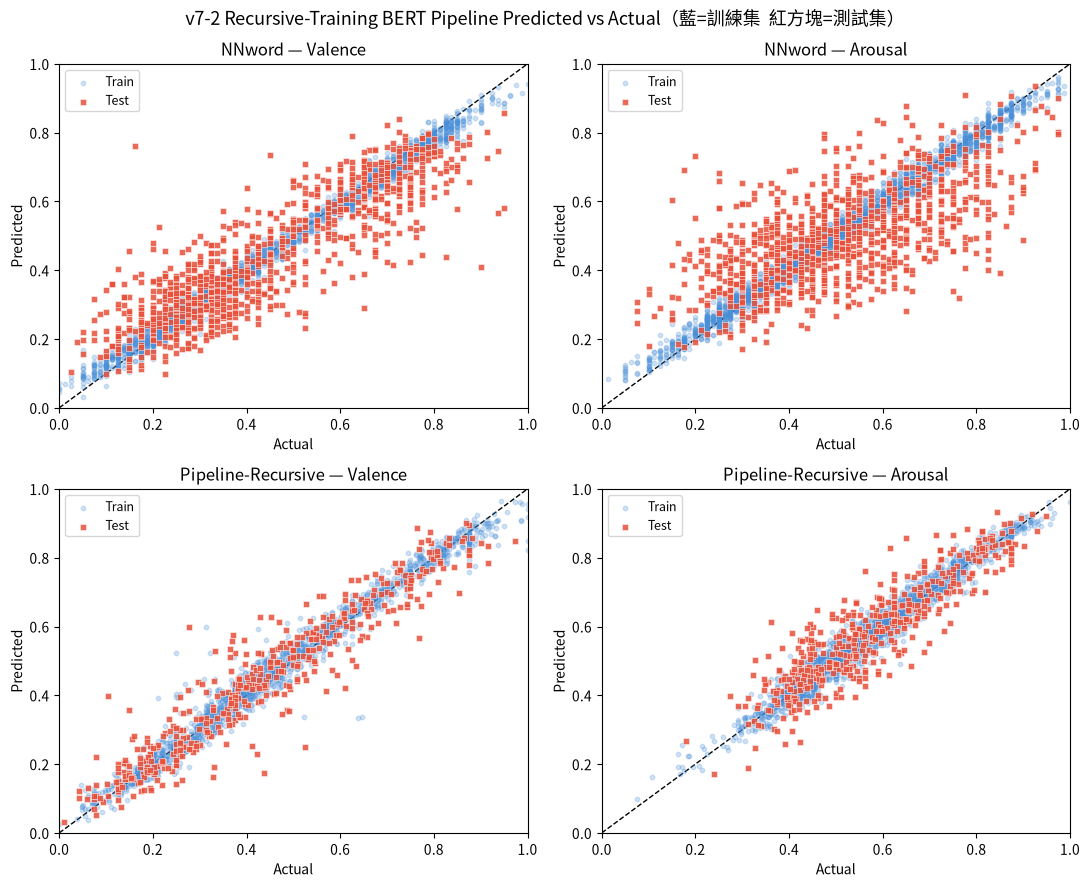

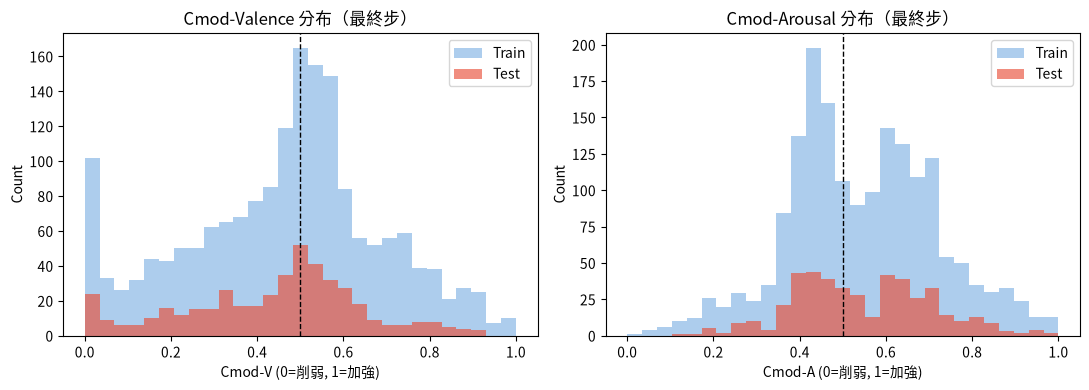

Test Cmod-V mean=0.438, std=0.206
Test Cmod-A mean=0.547, std=0.160


In [25]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
fig.suptitle('v7-2 Recursive-Training BERT Pipeline Predicted vs Actual（藍=訓練集  紅方塊=測試集）', fontsize=13)
configs = [
    (axes[0,0], pv_trw, word_train_val, pv_tew, word_test_val, 'NNword — Valence',   '#4A90D9', '#E8503A'),
    (axes[0,1], pa_trw, word_train_aro, pa_tew, word_test_aro, 'NNword — Arousal',   '#4A90D9', '#E8503A'),
    (axes[1,0], pv_trm, phrase_train_val, pv_tem, phrase_test_val, 'Pipeline-Recursive — Valence', '#4A90D9', '#E8503A'),
    (axes[1,1], pa_trm, phrase_train_aro, pa_tem, phrase_test_aro, 'Pipeline-Recursive — Arousal', '#4A90D9', '#E8503A'),
]
for ax, ptr, gtr, pte, gte, title, c_tr, c_te in configs:
    ax.scatter(gtr, ptr, alpha=0.25, s=10, color=c_tr, label='Train', zorder=2)
    ax.scatter(gte, pte, alpha=0.85, s=20, color=c_te, marker='s',
               edgecolors='white', linewidths=0.4, label='Test', zorder=3)
    ax.plot([0,1],[0,1],'k--', linewidth=1, zorder=1)
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
    ax.set_title(title); ax.legend(fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()
# c_mod 雙維度視覺化（Valence shift / Arousal shift）
_, _, cmv_tr, cma_tr = batch_predict_phrase_recursive(train_chain_samples, return_shift=True)
_, _, cmv_te, cma_te = batch_predict_phrase_recursive(test_chain_samples, return_shift=True)
fig2, axes2 = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0.0, 1.0, 30)
axes2[0].hist(cmv_tr, bins=bins, alpha=0.45, color='#4A90D9', label='Train')
axes2[0].hist(cmv_te, bins=bins, alpha=0.65, color='#E8503A', label='Test')
axes2[0].axvline(0.5, color='k', linestyle='--', linewidth=1)
axes2[0].set_title('Cmod-Valence 分布（最終步）')
axes2[0].set_xlabel('Cmod-V (0=削弱, 1=加強)')
axes2[0].set_ylabel('Count')
axes2[0].legend()
axes2[1].hist(cma_tr, bins=bins, alpha=0.45, color='#4A90D9', label='Train')
axes2[1].hist(cma_te, bins=bins, alpha=0.65, color='#E8503A', label='Test')
axes2[1].axvline(0.5, color='k', linestyle='--', linewidth=1)
axes2[1].set_title('Cmod-Arousal 分布（最終步）')
axes2[1].set_xlabel('Cmod-A (0=削弱, 1=加強)')
axes2[1].set_ylabel('Count')
axes2[1].legend()
plt.tight_layout(); plt.show()
print(f'Test Cmod-V mean={cmv_te.mean():.3f}, std={cmv_te.std():.3f}')
print(f'Test Cmod-A mean={cma_te.mean():.3f}, std={cma_te.std():.3f}')

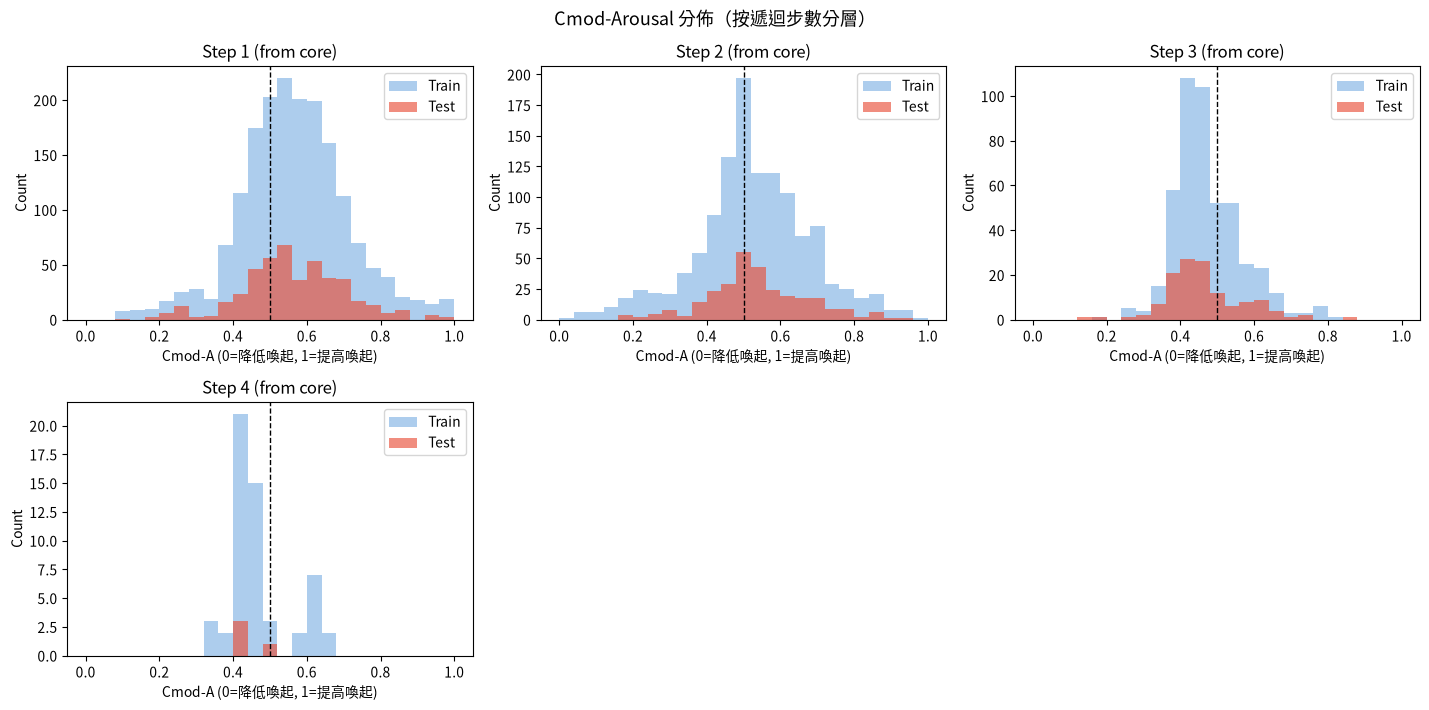

=== 每一步 Cmod-A 統計（Test）===
Step 1: mean=0.565, std=0.139, n=450
Step 2: mean=0.539, std=0.136, n=293
Step 3: mean=0.465, std=0.106, n=129
Step 4: mean=0.434, std=0.033, n=4


In [26]:
@torch.no_grad()
def collect_cmod_a_by_step(samples):
    model_word.eval()
    model_mod.eval()
    step_to_vals = {}
    for s in samples:
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        cur_v, cur_a = model_word(core_t)
        for step_idx, ctx_np in enumerate(s['ctx_chain'], start=1):
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, _, c_mod_a = model_mod(cur_v, cur_a, ctx_t)
            step_to_vals.setdefault(step_idx, []).append(c_mod_a.item())
    return {k: np.array(v, dtype=np.float32) for k, v in step_to_vals.items()}

train_a_by_step = collect_cmod_a_by_step(train_chain_samples)
test_a_by_step = collect_cmod_a_by_step(test_chain_samples)
all_steps = sorted(set(train_a_by_step.keys()) | set(test_a_by_step.keys()))
if not all_steps:
    raise ValueError('沒有可用的遞迴步數資料，請先確認 train_chain_samples / test_chain_samples。')
n_steps = len(all_steps)
n_cols = min(3, n_steps)
n_rows = int(np.ceil(n_steps / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.8 * n_cols, 3.6 * n_rows), squeeze=False)
bins = np.linspace(0.0, 1.0, 26)
for i, step in enumerate(all_steps):
    r = i // n_cols
    c = i % n_cols
    ax = axes[r, c]
    tr = train_a_by_step.get(step, np.array([], dtype=np.float32))
    te = test_a_by_step.get(step, np.array([], dtype=np.float32))
    if len(tr) > 0:
        ax.hist(tr, bins=bins, alpha=0.45, color='#4A90D9', label='Train')
    if len(te) > 0:
        ax.hist(te, bins=bins, alpha=0.65, color='#E8503A', label='Test')
    ax.axvline(0.5, color='k', linestyle='--', linewidth=1)
    ax.set_title(f'Step {step} (from core)')
    ax.set_xlabel('Cmod-A (0=降低喚起, 1=提高喚起)')
    ax.set_ylabel('Count')
    ax.legend()
for j in range(n_steps, n_rows * n_cols):
    rr = j // n_cols
    cc = j % n_cols
    axes[rr, cc].axis('off')
fig.suptitle('Cmod-Arousal 分佈（按遞迴步數分層）', fontsize=13)
plt.tight_layout()
plt.show()
print('=== 每一步 Cmod-A 統計（Test）===')
for step in all_steps:
    vals = test_a_by_step.get(step, np.array([], dtype=np.float32))
    if len(vals) == 0:
        continue
    print(f'Step {step}: mean={vals.mean():.3f}, std={vals.std():.3f}, n={len(vals)}')

## 14. Stage 3：擴充到 CVAS 句子層級（NNword / NNmod 完全不動，僅新增）

**設計原則（沿用 v7-2 的兩階段 Pipeline，往上疊一層，不改動任何既有 cell）：**
```
Stage 1（不動）：BERT(word) -> NNword -> Int(w)
Stage 2（不動）：BERT(core) -> NNword(frozen) -> Int(w)
                 BERT(modifier [SEP] core/phrase) -> NNmod(frozen) -> Int(mod phrase)
Stage 3（新增）：句子 -> 滑動窗口切出「情感詞」與「修飾詞+情感詞」候選 span
                 -> 每個 span 都走 Stage1+2 的遞迴鏈（NNword、NNmod 全程凍結，
                    只是「借用」它們算出來的 VA / c_mod，權重完全不變）
                 -> NNsent：用注意力機制學哪個 span 對整句 VA 貢獻最大
                 -> 加權聚合 -> 整句 VA
```

**「哪些詞有幫助 VA 預測、哪些沒作用」怎麼判斷（14.6）：**
1. **NNsent 的 attention weight** —— 句子「內部」的相對重要性（softmax 後同一句總和 = 1，
   沒辦法直接說某個詞「完全沒用」，只能說「比同句其他詞更／更不重要」）。
2. **Leave-One-Out（LOO）消融** —— 把某個 span 從句子中拿掉，重新跑一次 NNsent，
   量測整句 VA 的變化量 ΔV / ΔA。這是「絕對」、可以跨句子互相比較的貢獻量：
   ΔV/ΔA 接近 0，代表這個詞就算被 pipeline 抓進來、走完 NNword→NNmod，
   對這一句最終的 VA 判斷幾乎沒有影響。
3. 把兩者結合，並在整個測試集上依「情感詞（核心詞）」「修飾詞」分組取平均，
   就能得到一張「哪些詞平均而言有用／沒用」的排行榜（14.6 後半段）。

以下所有 cell 都只新增變數與函式（`extract_emotion_spans`、`run_full_pipeline`、`NNsent`…），
`NNword` / `NNmod` 兩個 class 與 `model_word` / `model_mod` 兩個訓練好的模型完全沒有被修改或重新訓練。

## 14.1 CVAS 前處理（正規化 + 切分，沿用 cell 5 的 `normalize_va`，不重新定義）

In [ ]:
# cell 3 只載入了 cvas，cell 5 只正規化/切分了 cvaw、cvap
# （v7-2 原版沒有用到 CVAS）；這裡把同一套流程套用在 cvas 上
cvas = normalize_va(cvas)
cvas_train, cvas_test = train_test_split(cvas, test_size=0.2, random_state=42)
print(f'CVAS 訓練:{len(cvas_train)}  測試:{len(cvas_test)}')
print(cvas_train[['Text', 'valence', 'arousal']].head().to_string(index=False))

## 14.2 句子 → 情感 span 切割 + Stage1+2 遞迴 Pipeline
借用 `model_word` / `model_mod` 的 VA 輸出，兩者權重完全不變。

In [ ]:
# 沿用 cell 5 的 split_phrase / cvaw_word_set / max_core_len，完全不改
# 沿用 cell 12 的 get_core_vec_cached / get_pair_vec_cached（BERT 向量快取，避免重算）
# 沿用 cell 10 定義、cell 14 / 16 訓練好的 model_word / model_mod（此處只做 eval，全程凍結）

MAX_SPANS  = 8   # 一句最多取幾個情感 span
MOD_WINDOW = 6   # 情感詞往前找修飾詞的視窗大小（字數）


@torch.no_grad()
def run_full_pipeline(span_text):
    """
    對一個文字片段（情感詞，或「修飾詞+情感詞」）執行完整 Stage1+2 遞迴鏈。
    NNword / NNmod 全程凍結、權重不變，這裡只是「借用」它們的推論結果。

    回傳：(V, A, c_mod_v, c_mod_a, has_modifier)
      has_modifier=1：有找到修飾詞，走完整 NNword -> NNmod 遞迴鏈
      has_modifier=0：只有核心詞，只有 NNword 的結果（NNmod 沒機會作用）
    """
    model_word.eval(); model_mod.eval()
    mod, core, chain = split_phrase(span_text, cvaw_word_set)

    if core is not None and mod:
        # 有修飾詞 → 完整遞迴鏈（跟 Stage2 訓練時走的路徑一致）
        ct = torch.tensor(get_core_vec_cached(core)).unsqueeze(0).to(device)
        cv, ca = model_word(ct)
        cur_label = core
        cmv = torch.tensor([[0.5]], device=device)
        cma = torch.tensor([[0.5]], device=device)
        for m in reversed(chain):
            ctx_t = torch.tensor(get_pair_vec_cached(str(m), cur_label)).unsqueeze(0).to(device)
            cv, ca, cmv, cma = model_mod(cv, ca, ctx_t)
            cur_label = str(m) + cur_label
        return cv.item(), ca.item(), cmv.item(), cma.item(), 1

    elif core is not None:
        # 只有核心詞、沒有修飾詞 → 只用 NNword
        ct = torch.tensor(get_core_vec_cached(core)).unsqueeze(0).to(device)
        cv, ca = model_word(ct)
        return cv.item(), ca.item(), 0.5, 0.5, 0

    else:
        # 這個片段裡沒有 CVAW 情感詞 → 直接對整段做 NNword 估計（fallback）
        vec = torch.tensor(get_bert_vec(span_text)).unsqueeze(0).to(device)
        cv, ca = model_word(vec)
        return cv.item(), ca.item(), 0.5, 0.5, 0


def extract_emotion_spans(sentence, cvaw_words, max_spans=MAX_SPANS, mod_window=MOD_WINDOW):
    """
    滑動窗口掃描句子：找出每個出現在 CVAW 詞典裡的情感詞，
    再往前嘗試組出「修飾詞+情感詞」的完整短語（用 split_phrase 驗證，
    且要求修飾詞鏈裡每個 token 都必須是 MODIFIER_LEXICON 認得的否定/程度詞，
    避免把句子裡任意的前置字誤判成修飾詞 —— split_phrase 的 fallback
    原本是為了短 CVAP 片語設計的，直接套在長很多的句子窗口上容易誤判）。

    沒被任何 span 涵蓋到的字，代表它從一開始就沒有進入 pipeline ——
    這本身就是「這個詞對 VA 預測沒有直接作用」的一種訊號
    （涵蓋率統計見 14.4 的 cnt_full / cnt_core / cnt_fb）。
    """
    sentence = str(sentence).strip()
    found_spans = []
    visited_pos = set()

    i = 0
    while i < len(sentence):
        matched_core = None
        matched_len = 0
        for cl in range(min(max_core_len, len(sentence) - i), 0, -1):
            if sentence[i:i + cl] in cvaw_words:
                matched_core = sentence[i:i + cl]
                matched_len = cl
                break

        if matched_core and i not in visited_pos:
            visited_pos.add(i)
            best_span = (matched_core, None, matched_core, [])
            for start in range(max(0, i - mod_window), i + 1):
                candidate = sentence[start:i + matched_len]
                m, c, ch = split_phrase(candidate, cvaw_words)
                # split_phrase() 的 fallback 會把「沒認得的字」也塞進 modifier_chain
                # （見 cell 5 split_modifier_chain 的 else 分支），對短 CVAP 片語還好，
                # 但套在長很多的句子窗口上，會把任意前綴字誤判成「修飾詞」。
                # 這裡額外要求 chain 裡每個 token 都必須是真正的否定/程度詞，
                # 才承認這是一個有效的「修飾詞+情感詞」span，否則視同沒找到修飾詞。
                if c == matched_core and m and ch and all(t in MODIFIER_LEXICON for t in ch):
                    best_span = (m + c, m, c, ch)
                    break
            if best_span[0] not in [s[0] for s in found_spans]:
                found_spans.append(best_span)
            i += matched_len
        else:
            i += 1

    if not found_spans:
        found_spans = [(sentence, None, None, [])]

    return found_spans[:max_spans]


print('extract_emotion_spans / run_full_pipeline 定義完成')

## 14.3 NNsent：句子層級聚合（新模型；NNword / NNmod 完全不受影響）

輸入（全部來自 Stage1+2 Pipeline 的結果，不是原始 BERT 向量）：
- `span_vas`   `(B, MAX_SPANS, 2)` — 每個 span 最終的 VA
- `span_cmods` `(B, MAX_SPANS, 2)` — NNmod 的 `c_mod`（修飾詞把 VA 推的方向與強度）
- `span_hits`  `(B, MAX_SPANS, 1)` — 1 = 有修飾詞、走完整 NNword→NNmod 鏈；0 = 只有核心詞
- `span_mask`  `(B, MAX_SPANS)`    — 有效 span 的遮罩

注意力邏輯：`c_mod` 離 0.5 越遠代表修飾詞的作用越大，`hit=0` 代表這個 span 沒有修飾詞可用，
模型會學著調整每個 span 該拿到多少注意力 —— 這組注意力權重，就是 14.6 用來判斷
「哪些詞有幫助」的其中一個訊號。

In [ ]:
class NNsent(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        # 注意力：[VA(2), c_mod(2), hit(1)] = 5 維
        self.attn_fc = nn.Sequential(
            nn.Linear(5, hidden), nn.Tanh(), nn.Linear(hidden, 1)
        )
        # VA 預測頭：加權VA(2) + 全局VA(2) = 4 維
        self.val_head = nn.Sequential(
            nn.Linear(4, 32), nn.LayerNorm(32), nn.ReLU(),
            nn.Linear(32, 1), nn.Sigmoid()
        )
        # Arousal 多吃 Valence（建模 VA 相關性）
        self.aro_head = nn.Sequential(
            nn.Linear(5, 32), nn.LayerNorm(32), nn.ReLU(),
            nn.Linear(32, 1), nn.Sigmoid()
        )

    def forward(self, span_vas, span_cmods, span_hits, span_mask):
        attn_feat = torch.cat([span_vas, span_cmods, span_hits], dim=-1)   # (B, S, 5)
        attn_score = self.attn_fc(attn_feat).squeeze(-1)                   # (B, S)
        attn_score = attn_score.masked_fill(span_mask == 0, float('-inf'))
        attn_weight = torch.softmax(attn_score, dim=1)                     # (B, S)

        weighted_va = (attn_weight.unsqueeze(-1) * span_vas).sum(dim=1)    # (B, 2)
        mask_sum = span_mask.sum(dim=1, keepdim=True).clamp(min=1.0)
        global_va = (span_vas * span_mask.unsqueeze(-1)).sum(dim=1) / mask_sum

        fused = torch.cat([weighted_va, global_va], dim=-1)                # (B, 4)
        val = self.val_head(fused)
        aro = self.aro_head(torch.cat([fused, val.detach()], dim=-1))
        return val, aro, attn_weight


print('NNsent（Stage 3）定義完成')

## 14.4 建立 CVAS pipeline span 樣本 + 訓練 NNsent（NNword、NNmod 全程凍結）

In [ ]:
def build_cvas_pipeline_samples(df, max_spans=MAX_SPANS):
    """
    對 CVAS 每一句建立 Stage 3 的輸入樣本：
      span_vas / span_cmods / span_hits / span_mask —— 餵給 NNsent
      span_infos —— 每個 span 的文字資訊（span 文字、核心詞、修飾詞、hit），
                     只給 14.6 的重要性分析用，不進模型
    """
    samples = []
    cnt_full = cnt_core = cnt_fb = 0
    total = 0

    for _, row in df.iterrows():
        sentence = str(row['Text'])
        span_items = extract_emotion_spans(sentence, cvaw_word_set, max_spans)

        span_vas = np.zeros((max_spans, 2), dtype=np.float32)
        span_cmods = np.full((max_spans, 2), 0.5, dtype=np.float32)
        span_hits = np.zeros((max_spans, 1), dtype=np.float32)
        span_mask = np.zeros(max_spans, dtype=np.float32)
        span_infos = []

        for i, (span_text, mod, core, chain) in enumerate(span_items):
            sv, sa, cmv, cma, hit = run_full_pipeline(span_text)
            span_vas[i] = [sv, sa]
            span_cmods[i] = [cmv, cma]
            span_hits[i] = hit
            span_mask[i] = 1.0
            span_infos.append({
                'span_text': span_text, 'modifier': mod, 'core_word': core, 'hit': hit,
            })
            if mod:
                cnt_full += 1
            elif core:
                cnt_core += 1
            else:
                cnt_fb += 1
            total += 1

        samples.append({
            'span_vas': span_vas, 'span_cmods': span_cmods,
            'span_hits': span_hits, 'span_mask': span_mask,
            'span_infos': span_infos,
            'valence': float(row['valence']), 'arousal': float(row['arousal']),
            'sentence': sentence,
        })

    print(f'  完整Pipeline（修飾詞+核心詞）: {cnt_full}/{total} ({cnt_full/max(total,1)*100:.1f}%)')
    print(f'  只有核心詞（無修飾詞）:        {cnt_core}/{total} ({cnt_core/max(total,1)*100:.1f}%)')
    print(f'  Fallback（不在 CVAW 詞典內）:  {cnt_fb}/{total} ({cnt_fb/max(total,1)*100:.1f}%)')
    return samples


print('計算 CVAS 訓練集 span...')
cvas_train_samples = build_cvas_pipeline_samples(cvas_train)
print('計算 CVAS 測試集 span...')
cvas_test_samples = build_cvas_pipeline_samples(cvas_test)


def pack_to_dataset(samples):
    return TensorDataset(
        torch.tensor(np.stack([s['span_vas'] for s in samples])).float(),
        torch.tensor(np.stack([s['span_cmods'] for s in samples])).float(),
        torch.tensor(np.stack([s['span_hits'] for s in samples])).float(),
        torch.tensor(np.stack([s['span_mask'] for s in samples])).float(),
        torch.tensor(np.array([[s['valence'], s['arousal']] for s in samples])).float(),
    )


cvas_train_ds = pack_to_dataset(cvas_train_samples)
cvas_test_ds = pack_to_dataset(cvas_test_samples)
cvas_train_dl = DataLoader(cvas_train_ds, batch_size=32, shuffle=True)
cvas_test_dl = DataLoader(cvas_test_ds, batch_size=32, shuffle=False)

cvas_train_val = np.array([s['valence'] for s in cvas_train_samples], dtype=np.float32)
cvas_train_aro = np.array([s['arousal'] for s in cvas_train_samples], dtype=np.float32)
cvas_test_val = np.array([s['valence'] for s in cvas_test_samples], dtype=np.float32)
cvas_test_aro = np.array([s['arousal'] for s in cvas_test_samples], dtype=np.float32)
print(f'CVAS pipeline 樣本: 訓練={len(cvas_train_samples)}  測試={len(cvas_test_samples)}')

In [ ]:
model_sent = NNsent(hidden=64).to(device)
for p in model_word.parameters():
    p.requires_grad = False
for p in model_mod.parameters():
    p.requires_grad = False

opt_sent = optim.Adam(model_sent.parameters(), lr=1e-3)
sch_sent = optim.lr_scheduler.CosineAnnealingLR(opt_sent, T_max=50)
criterion = nn.MSELoss()

print('=== Stage 3：訓練 NNsent（NNword + NNmod 全程凍結，只借用它們的 VA 輸出）===')
N_EPOCHS_SENT = 50
losses_s = []
for epoch in range(N_EPOCHS_SENT):
    model_sent.train()
    total_loss = 0.0
    for sv, sc, sh, sm, labels in cvas_train_dl:
        sv, sc, sh, sm = sv.to(device), sc.to(device), sh.to(device), sm.to(device)
        yv = labels[:, 0:1].to(device)
        ya = labels[:, 1:2].to(device)
        pv, pa, _ = model_sent(sv, sc, sh, sm)
        loss = criterion(pv, yv) + criterion(pa, ya)
        opt_sent.zero_grad()
        loss.backward()
        opt_sent.step()
        total_loss += loss.item()
    sch_sent.step()
    losses_s.append(total_loss / len(cvas_train_dl))
    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_SENT} | Loss: {losses_s[-1]:.6f}')

plt.figure(figsize=(8, 3))
plt.plot(losses_s)
plt.title('Stage 3 NNsent Training Loss')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.tight_layout(); plt.show()

for p in model_word.parameters():
    p.requires_grad = True
for p in model_mod.parameters():
    p.requires_grad = True
print('Stage 3 完成（NNword / NNmod 權重全程未被更新）')

## 14.5 三階段完整評估（NNword / Pipeline / NNsent）

In [ ]:
@torch.no_grad()
def batch_predict_sent(dl):
    model_sent.eval()
    all_pv, all_pa = [], []
    for sv, sc, sh, sm, _ in dl:
        pv, pa, _ = model_sent(sv.to(device), sc.to(device), sh.to(device), sm.to(device))
        all_pv.append(pv.cpu().numpy())
        all_pa.append(pa.cpu().numpy())
    return np.concatenate(all_pv).flatten(), np.concatenate(all_pa).flatten()


pv_str, pa_str = batch_predict_sent(cvas_train_dl)
pv_ste, pa_ste = batch_predict_sent(cvas_test_dl)

print('=' * 75)
print('【Stage 3：CVAS 句子層級評估】')
print('=' * 75)
print('\n[NNsent] CVAS 訓練集')
compute_metrics(pv_str, cvas_train_val, 'Valence')
compute_metrics(pa_str, cvas_train_aro, 'Arousal')
print('\n[NNsent] CVAS 測試集')
compute_metrics(pv_ste, cvas_test_val, 'Valence')
compute_metrics(pa_ste, cvas_test_aro, 'Arousal')

rows_cvas = [
    ('NNsent', '訓練', 'Valence', *metrics(pv_str, cvas_train_val)),
    ('NNsent', '訓練', 'Arousal', *metrics(pa_str, cvas_train_aro)),
    ('NNsent', '測試', 'Valence', *metrics(pv_ste, cvas_test_val)),
    ('NNsent', '測試', 'Arousal', *metrics(pa_ste, cvas_test_aro)),
]
summary_cvas = pd.DataFrame(
    rows_cvas,
    columns=['模型', '資料集', '維度', 'MAE', 'MSE', 'Pearson r', 'Kendall τ', 'Spearman ρ'],
)
summary_all = pd.concat([summary, summary_cvas], ignore_index=True)
print('\n三階段（NNword / Pipeline / NNsent）合併總表：')
print(summary_all.to_string(index=False))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle('Stage 3 NNsent — CVAS Predicted vs Actual（藍=訓練集 紅方塊=測試集）', fontsize=13)
configs_sent = [
    (axes[0], pv_str, cvas_train_val, pv_ste, cvas_test_val, 'NNsent — Valence'),
    (axes[1], pa_str, cvas_train_aro, pa_ste, cvas_test_aro, 'NNsent — Arousal'),
]
for ax, ptr, gtr, pte, gte, title in configs_sent:
    ax.scatter(gtr, ptr, alpha=0.25, s=10, color='#4A90D9', label='Train', zorder=2)
    ax.scatter(gte, pte, alpha=0.85, s=20, color='#E8503A', marker='s',
               edgecolors='white', linewidths=0.4, label='Test', zorder=3)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, zorder=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
    ax.set_title(title); ax.legend(fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()

## 14.6 哪些詞有幫助、哪些沒作用：Leave-One-Out 消融 + attention 排行榜

作法：對每個句子，先用全部 span 跑一次 NNsent 得到「完整句子」的 VA；
再對每個 span 輪流「假裝它不存在」（`span_mask` 該位置設 0）重跑一次 NNsent，
比較兩次 VA 的差距 `ΔV / ΔA`。

這裡完全沒有重跑 BERT / NNword / NNmod —— 每個 span 的 VA、c_mod 早就在 14.4
算好存在 `sample['span_vas']` / `sample['span_cmods']` 裡了，Leave-One-Out
只是把 `span_mask` 換一下、重跑一次很小的 NNsent，所以對整個測試集做也很快。

In [ ]:
@torch.no_grad()
def _nnsent_forward_from_sample(sample, mask_override=None):
    sv = torch.tensor(sample['span_vas']).unsqueeze(0).to(device)
    sc = torch.tensor(sample['span_cmods']).unsqueeze(0).to(device)
    sh = torch.tensor(sample['span_hits']).unsqueeze(0).to(device)
    mask = sample['span_mask'] if mask_override is None else mask_override
    sm = torch.tensor(mask).unsqueeze(0).to(device)
    v, a, attn = model_sent(sv, sc, sh, sm)
    return v.item(), a.item(), attn[0].cpu().numpy()


@torch.no_grad()
def compute_span_importance(sample):
    """
    對一個 CVAS 樣本（含 span_vas/span_cmods/span_hits/span_mask/span_infos）
    計算每個有效 span 的：
      attn_weight — NNsent 內部的相對注意力（同一句總和 = 1）
      delta_v/delta_a — Leave-One-Out：拿掉這個 span 後，整句 VA 的絕對變化量
      impact — sqrt(delta_v^2 + delta_a^2)，整合 V/A 兩軸的重要性分數
    """
    model_sent.eval()
    full_v, full_a, attn = _nnsent_forward_from_sample(sample)
    n_valid = int(sample['span_mask'].sum())
    results = []
    for i in range(n_valid):
        loo_mask = sample['span_mask'].copy()
        loo_mask[i] = 0.0
        if loo_mask.sum() == 0:
            # 只剩這一個 span 時，拿掉後沒東西可聚合 —— 視為退回中性值 0.5
            loo_v, loo_a = 0.5, 0.5
        else:
            loo_v, loo_a, _ = _nnsent_forward_from_sample(sample, mask_override=loo_mask)
        delta_v = full_v - loo_v
        delta_a = full_a - loo_a
        results.append({
            'span_text': sample['span_infos'][i]['span_text'],
            'core_word': sample['span_infos'][i]['core_word'],
            'modifier': sample['span_infos'][i]['modifier'],
            'hit': sample['span_infos'][i]['hit'],
            'attn_weight': float(attn[i]),
            'delta_v': float(delta_v),
            'delta_a': float(delta_a),
            'impact': float(np.sqrt(delta_v ** 2 + delta_a ** 2)),
        })
    return full_v, full_a, results


print('compute_span_importance 定義完成')

### 全測試集彙整：資料驅動的「有幫助 / 普通 / 沒作用」門檻

In [ ]:
print('對整個 CVAS 測試集跑 Leave-One-Out 消融（只重跑 NNsent，很快）...')
all_span_rows = []
for s in cvas_test_samples:
    _, _, span_results = compute_span_importance(s)
    for r in span_results:
        r['sentence'] = s['sentence']
        all_span_rows.append(r)

span_df = pd.DataFrame(all_span_rows)
print(f'共分析 {len(span_df)} 個 span（來自 {len(cvas_test_samples)} 個測試句子）')

# 用整個測試集的 impact 分布切三分位，當作「有幫助 / 普通 / 沒作用」的資料驅動門檻
# （用分位數而不是寫死的絕對值，因為 impact 的尺度會隨資料集、模型調整）
q_low, q_high = span_df['impact'].quantile([0.33, 0.67])


def label_usefulness(impact):
    if impact >= q_high:
        return '有幫助'
    if impact <= q_low:
        return '沒作用'
    return '普通'


span_df['usefulness'] = span_df['impact'].apply(label_usefulness)
print(f'\nimpact 三分位門檻: 33%={q_low:.4f}  67%={q_high:.4f}')
print(span_df['usefulness'].value_counts())

### 依「情感詞（核心詞）」與「修飾詞」分組的重要性排行榜

In [ ]:
print('=== 依「情感詞（核心詞）」分組：平均對整句 VA 的貢獻 ===')
core_rank = (
    span_df[span_df['core_word'].notna()]
    .groupby('core_word')
    .agg(n=('impact', 'size'),
         mean_impact=('impact', 'mean'),
         mean_attn=('attn_weight', 'mean'),
         mean_dV=('delta_v', 'mean'),
         mean_dA=('delta_a', 'mean'))
    .query('n >= 2')
    .sort_values('mean_impact', ascending=False)
)
print('\n【最有幫助的情感詞（平均 impact 最高，前 20）】')
print(core_rank.head(20).to_string())
print('\n【幾乎沒作用的情感詞（平均 impact 最低，前 20 —— 即使被抓進 pipeline 也不太影響整句 VA）】')
print(core_rank.tail(20).sort_values('mean_impact').to_string())

print('\n=== 依「修飾詞」分組：平均對整句 VA 的貢獻 ===')
mod_rank = (
    span_df[span_df['modifier'].notna()]
    .groupby('modifier')
    .agg(n=('impact', 'size'),
         mean_impact=('impact', 'mean'),
         mean_attn=('attn_weight', 'mean'),
         mean_dV=('delta_v', 'mean'),
         mean_dA=('delta_a', 'mean'))
    .query('n >= 2')
    .sort_values('mean_impact', ascending=False)
)
print(mod_rank.to_string())

core_rank.to_csv('cvas_core_word_importance.csv', encoding='utf-8-sig')
mod_rank.to_csv('cvas_modifier_importance.csv', encoding='utf-8-sig')
span_df.to_csv('cvas_span_importance_raw.csv', index=False, encoding='utf-8-sig')
print('\n已輸出：cvas_core_word_importance.csv / cvas_modifier_importance.csv / cvas_span_importance_raw.csv')

### 單句 Demo：逐 span 列出 attention + LOO 貢獻 + 有幫助/沒作用 標籤

In [ ]:
@torch.no_grad()
def predict_sentence_with_importance(sentence, verbose=True):
    """
    句子推論 + 逐 span 重要性分析：
      attn   = NNsent 內部注意力（句內相對值，同一句總和 = 1）
      DV/DA  = 把這個 span 拿掉後，整句 VA 的絕對變化量（Leave-One-Out）
      impact = sqrt(DV^2+DA^2)，用整個測試集算出的三分位數決定「有幫助/普通/沒作用」
    """
    model_word.eval(); model_mod.eval(); model_sent.eval()
    span_items = extract_emotion_spans(sentence, cvaw_word_set)

    span_vas = np.zeros((MAX_SPANS, 2), dtype=np.float32)
    span_cmods = np.full((MAX_SPANS, 2), 0.5, dtype=np.float32)
    span_hits = np.zeros((MAX_SPANS, 1), dtype=np.float32)
    span_mask = np.zeros(MAX_SPANS, dtype=np.float32)
    span_infos = []

    for i, (span_text, mod, core, chain) in enumerate(span_items):
        sv, sa, cmv, cma, hit = run_full_pipeline(span_text)
        span_vas[i] = [sv, sa]
        span_cmods[i] = [cmv, cma]
        span_hits[i] = hit
        span_mask[i] = 1.0
        span_infos.append({'span_text': span_text, 'modifier': mod, 'core_word': core, 'hit': hit})

    sample = {
        'span_vas': span_vas, 'span_cmods': span_cmods,
        'span_hits': span_hits, 'span_mask': span_mask, 'span_infos': span_infos,
    }
    full_v, full_a, span_results = compute_span_importance(sample)

    fv9 = round(full_v * 8 + 1, 3)
    fa9 = round(full_a * 8 + 1, 3)
    pol = '正向' if full_v > 0.625 else ('負向' if full_v < 0.375 else '中性')
    act = '高喚起' if full_a > 0.625 else ('低喚起' if full_a < 0.375 else '中喚起')

    if verbose:
        print(f'\n句子：「{sentence}」')
        print(f'整句 VA（1-9）→ Valence={fv9}  Arousal={fa9}  [{pol}/{act}]\n')
        print(f'{"span":16s} {"attn":>7} {"DV":>8} {"DA":>8} {"impact":>8}  判斷')
        print('-' * 60)
        for r in sorted(span_results, key=lambda x: -x['impact']):
            tag = label_usefulness(r['impact'])
            print(f'{r["span_text"]:16s} {r["attn_weight"]:7.3f} '
                  f'{r["delta_v"]:8.4f} {r["delta_a"]:8.4f} {r["impact"]:8.4f}  {tag}')
    return fv9, fa9, span_results


print('\n=== 句子推論 + 逐詞重要性 Demo ===')
for s in [
    '這次旅行真的非常開心，風景美極了！',
    '主治醫師強調血液透析，家屬却遲遲無法達到共識。',
    '視病如親，讓我十分的動容。',
    '雖然考試沒過，但心情還算平靜。',
    '非常憤怒，完全無法接受這種行為！',
]:
    predict_sentence_with_importance(s)